# P5 - Deteksi Tepi (SIMUTEH v0.2-tepi)
**Nama:** Muhammad Fahmi | **NIM:** 2330511082 | **Kelas:** TI-7B | **SEED:** 1986 | Repository: `simuteh-2330511082`

Praproses: `praproses.py` milik sendiri (konfigurasi E dari Evaluasi P1-P4, `hasil/param_praproses.json`). Ukuran evaluasi: presisi, recall, F1 tepi dengan toleransi 2 piksel.

## Bagian 1. Gradien Citra dan Operator Tepi
### Langkah 1.1 Lembar hitung manual (potongan A)
Kernel diterapkan sebagai korelasi. Piksel tengah A = 58.

**a) Sobel.** Gx = (-52 + 180) + (-2·50 + 2·185) + (-54 + 190) = 128 + 270 + 136 = **534**. Gy = (-52 - 2·55 - 180) + (54 + 2·60 + 190) = -342 + 364 = **22**.  
|G| = √(534² + 22²) = √285640 = **534,45**; |Gx|+|Gy| = **556**; θ = atan2(22, 534) = **2,36°**.

**b) Prewitt.** Gx = 128 + 135 + 136 = **399**; Gy = -(52+55+180) + (54+60+190) = -287 + 304 = **17**.  
|G| = **399,36**; |Gx|+|Gy| = 416; θ = 2,44°. Rasio |G| Sobel : Prewitt = 534,45 / 399,36 = **1,338 ≈ 4/3** (bobot pusat 2 membuat jumlah bobot positif 4, bukan 3).

**c) Laplacian.** 55 + 50 + 185 + 60 - 4·58 = 350 - 232 = **+118**. Positif berarti piksel pusat lebih gelap daripada rerata empat tetangganya: piksel berada di sisi gelap tepi. Tanda berganti (+ ke -) saat menyeberangi tepi; titik pergantian itulah perlintasan nol.

**d)** Arah gradien ≈ 2,4° (hampir sepanjang sumbu x, menuju sisi terang). Arah tepi tegak lurus gradien, yaitu ≈ **92,4° (hampir vertikal)**, sesuai batas daun-bercak yang berupa garis tegak.

Verifikasi dengan kode ada pada sel berikut.

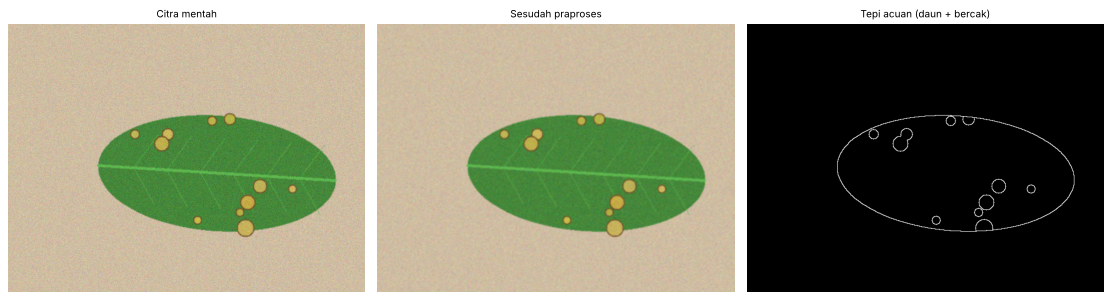

In [1]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 80
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
plt.savefig("../hasil/p5_persiapan.png", bbox_inches="tight"); plt.show()

In [2]:
# Verifikasi lembar hitung 1.1 dengan kode
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], float)
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float); Ky = Kx.T
Px = np.array([[-1, 0, 1]] * 3, float); Py = Px.T
Lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float)
for nm, kx, ky in [("Sobel", Kx, Ky), ("Prewitt", Px, Py)]:
    gx, gy = (A * kx).sum(), (A * ky).sum()
    print(f"{nm:8s} Gx={gx:.0f} Gy={gy:.0f} |G|={np.hypot(gx, gy):.2f} |Gx|+|Gy|={abs(gx)+abs(gy):.0f} "
          f"theta={np.degrees(np.arctan2(gy, gx)):.2f} derajat")
print("Rasio |G| Sobel/Prewitt:", round(np.hypot((A*Kx).sum(), (A*Ky).sum()) / np.hypot((A*Px).sum(), (A*Py).sum()), 3))
print("Laplacian pusat:", (A * Lap).sum())

Sobel    Gx=534 Gy=22 |G|=534.45 |Gx|+|Gy|=556 theta=2.36 derajat
Prewitt  Gx=399 Gy=17 |G|=399.36 |Gx|+|Gy|=416 theta=2.44 derajat
Rasio |G| Sobel/Prewitt: 1.338
Laplacian pusat: 118.0


### Langkah 1.2 Gradien Sobel manual vs `cv2.Sobel`
Selisih maksimum 0,0: korelasi dengan kernel manual identik dengan fungsi pustaka. Panel arah menunjukkan tepi vertikal (batas kiri/kanan elips) berarah sekitar 0° atau ±180°, tepi horizontal berarah ±90°.

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 498.9


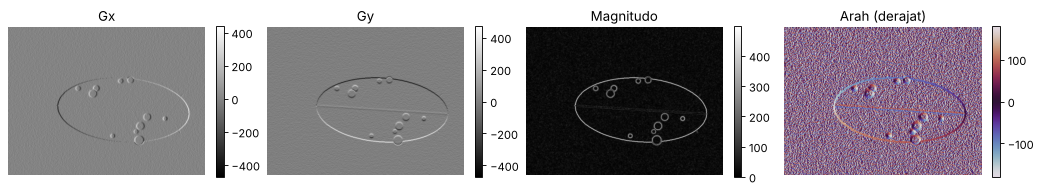

In [3]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien.png", bbox_inches="tight"); plt.show()

### Langkah 1.3 Empat operator pada satu citra

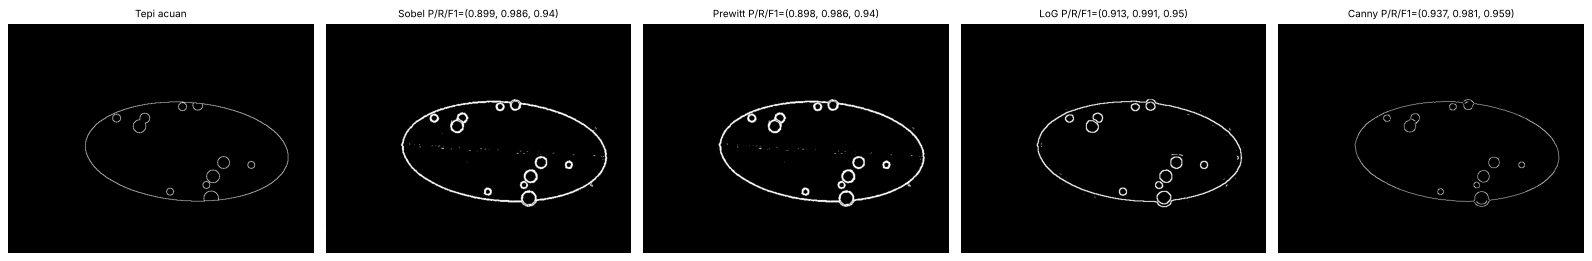

In [4]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil([acuan] + list(hasil.values()),
       ["Tepi acuan"] + [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()], ukuran=(20, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", bbox_inches="tight"); plt.show()

### Langkah 1.4 Perbandingan menyeluruh (Tabel 6) - 40 citra berbercak

In [5]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)
print("\nTABEL 6 (rerata F1):")
t6 = tabel_tepi.pivot_table(index="metode", columns=["sumber", "kanal"], values="F1").round(3)
t6 = t6.loc[["Sobel", "Prewitt", "LoG", "Canny"]]
print(t6)
t6.to_csv("../hasil/p5_tabel6.csv")

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.728  0.753  0.738
                LoG      0.622  0.996  0.759
                Prewitt  0.747  0.960  0.827
                Sobel    0.711  0.967  0.801
          R     Canny    0.982  0.978  0.979
                LoG      0.893  0.997  0.933
                Prewitt  0.551  0.995  0.647
                Sobel    0.498  0.995  0.596
praproses Gray  Canny    0.736  0.755  0.744
                LoG      0.614  0.996  0.751
                Prewitt  0.857  0.852  0.797
                Sobel    0.853  0.861  0.805
          R     Canny    0.981  0.968  0.972
                LoG      0.898  0.997  0.936
                Prewitt  0.866  0.980  0.911
                Sobel    0.846  0.982  0.897

TABEL 6 (rerata F1):
sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                                
Sobel    0.801  0.596     0.805  0.897
Prewitt  0.8

### Langkah 1.5 (Kerjakan sendiri) Grafik F1 per kondisi cahaya

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
bayangan        0.860    0.880  0.968  0.982
gelap           0.839    0.858  0.956  0.982
kontras_rendah  0.950    0.948  0.816  0.916
normal          0.964    0.965  0.980  0.990
terang          0.872    0.902  0.961  0.991


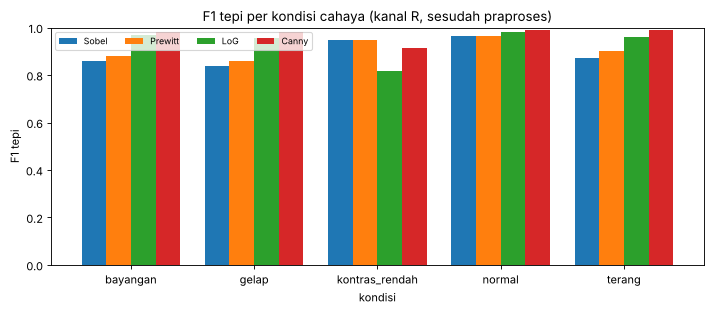

In [6]:
# Langkah 1.5 (kerjakan sendiri): F1 per kondisi cahaya, kanal R sesudah praproses
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
pv = sub.pivot_table(index="kondisi", columns="metode", values="F1")[["Sobel", "Prewitt", "LoG", "Canny"]]
print(pv.round(3))
pv.plot.bar(figsize=(9, 4), rot=0, width=0.8)
plt.ylabel("F1 tepi"); plt.title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
plt.ylim(0, 1); plt.legend(ncol=4, fontsize=8); plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", bbox_inches="tight"); plt.show()

### Bukti tambahan untuk P1.2 dan P1.5 (Sobel vs Prewitt, pengaruh sigma/ambang LoG)

In [7]:
# Bukti tambahan untuk P1.2 dan P1.5
# (a) Sobel vs Prewitt: rasio magnitudo pada kanal R satu citra, dan efek ambang yang sama
g = pra[:, :, 2].astype(np.float32)
ms = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
pxk = np.array([[-1, 0, 1]] * 3, np.float32)
mp = np.hypot(cv2.filter2D(g, -1, pxk), cv2.filter2D(g, -1, pxk.T))
tepi = ms > 100
print("rasio median |G| Sobel/Prewitt pada piksel tepi:", round(float(np.median(ms[tepi] / np.maximum(mp[tepi], 1e-6))), 3))
rows = []
for nm, T in [("Sobel T=100", 100), ("Prewitt T=100 (sama)", 100), ("Prewitt T=75", 75)]:
    m = ms if nm.startswith("Sobel") else mp
    e = ((m > T) * 255).astype(np.uint8)
    rows.append([nm, int((e > 0).sum()), *skor_tepi(e, acuan)])
print(pd.DataFrame(rows, columns=["operator", "piksel_tepi", "P", "R", "F1"]))
# (b) LoG: pengaruh sigma dan ambang (frac)
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im, md_, mb_ = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md_), tepi_acuan(mb_))
    gg = praproses(im, PARAM)[:, :, 2]
    for sg in [1.0, 3.0]:
        for fr in [0.0, 0.05, 0.2]:
            baris.append([sg, fr, *skor_tepi(tepi_log(gg, sg, fr), ac)])
logt = pd.DataFrame(baris, columns=["sigma", "frac", "P", "R", "F1"]).groupby(["sigma", "frac"]).mean().round(3)
print(logt)

rasio median |G| Sobel/Prewitt pada piksel tepi: 1.341
               operator  piksel_tepi      P      R    F1
0           Sobel T=100         6254  0.899  0.986  0.94
1  Prewitt T=100 (sama)         5161  0.937  0.985  0.96
2          Prewitt T=75         6314  0.898  0.986  0.94


                P      R     F1
sigma frac                     
1.0   0.00  0.014  1.000  0.028
      0.05  0.015  1.000  0.029
      0.20  0.049  0.999  0.091
3.0   0.00  0.024  0.998  0.046
      0.05  0.128  0.998  0.213
      0.20  0.898  0.997  0.936


In [8]:
# Pemeriksaan per kondisi untuk P1.4 (efek praproses pada presisi/recall)
a = tabel_tepi.groupby(["kanal", "metode", "sumber", "kondisi"])[["P", "R"]].mean().round(3)
print(a.loc[("Gray", "Sobel")]); print(a.loc[("Gray", "Prewitt")]); print(a.loc[("R", "Canny")]); print(a.loc[("R", "Sobel")])

                              P      R
sumber    kondisi                     
mentah    bayangan        0.734  0.991
          gelap           0.668  0.998
          kontras_rendah  0.723  0.852
          normal          0.615  0.997
          terang          0.814  0.996
praproses bayangan        0.772  0.994
          gelap           0.788  0.997
          kontras_rendah  0.966  0.323
          normal          0.822  0.996
          terang          0.916  0.996
                              P      R
sumber    kondisi                     
mentah    bayangan        0.772  0.990
          gelap           0.684  0.997
          kontras_rendah  0.766  0.821
          normal          0.654  0.997
          terang          0.859  0.996
praproses bayangan        0.780  0.994
          gelap           0.794  0.997
          kontras_rendah  0.958  0.277
          normal          0.828  0.996
          terang          0.923  0.996
                              P      R
sumber    kondisi        

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi
### Langkah 2.1 Lembar hitung manual
**(a) NMS.** Piksel tengah M1 = 100; M2 = 80.

| Matriks | Arah gradien 0° (bandingkan kiri-kanan) | Arah gradien 90° (bandingkan atas-bawah) |
|---|---|---|
| M1 | 100 ≥ 90 dan 100 ≥ 95 → **dipertahankan** | 100 ≥ 40 dan 100 ≥ 30 → **dipertahankan** |
| M2 | 80 < 85 → **ditekan (0)** | 80 ≥ 60 dan 80 ≥ 45 → **dipertahankan** |

**(b) Hysteresis** (bawah = 50, atas = 100) pada `[20, 60, 120, 80, 40, 90, 30]`:

- Piksel kuat (≥ 100): indeks 2 (120).
- Piksel lemah (50 sampai < 100): indeks 1 (60), 3 (80), 5 (90). Nilai 20, 40, 30 < 50 → bukan tepi.
- Lemah yang terhubung ke kuat: indeks 1 dan 3 (bersebelahan dengan indeks 2). Indeks 5 (90) terpisah oleh indeks 4 (40 < 50) → dibuang.
- **Tepi akhir: `[0, 1, 1, 1, 0, 0, 0]`**.

In [9]:
# Verifikasi lembar hitung 2.1
M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]]); M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])
for nm, M in [("M1", M1), ("M2", M2)]:
    c = M[1, 1]
    print(nm, "arah 0 deg (kiri-kanan):", "dipertahankan" if c >= M[1, 0] and c >= M[1, 2] else "ditekan",
          "| arah 90 deg (atas-bawah):", "dipertahankan" if c >= M[0, 1] and c >= M[2, 1] else "ditekan")
baris_ = np.array([20, 60, 120, 80, 40, 90, 30]); lo, hi = 50, 100
kuat = baris_ >= hi; lemah = (baris_ >= lo) & ~kuat
akhir = kuat.copy(); berubah = True
while berubah:
    baru = akhir | (lemah & (np.roll(akhir, 1) | np.roll(akhir, -1)))
    baru[0] = akhir[0] | (lemah[0] & akhir[1]); baru[-1] = akhir[-1] | (lemah[-1] & akhir[-2])
    berubah = (baru != akhir).any(); akhir = baru
print("kuat :", kuat.astype(int)); print("lemah:", lemah.astype(int)); print("akhir:", akhir.astype(int))

M1 arah 0 deg (kiri-kanan): dipertahankan | arah 90 deg (atas-bawah): dipertahankan
M2 arah 0 deg (kiri-kanan): ditekan | arah 90 deg (atas-bawah): dipertahankan
kuat : [0 0 1 0 0 0 0]
lemah: [0 1 0 1 0 1 0]
akhir: [0 1 1 1 0 0 0]


### Langkah 2.2 Pengaruh sigma dan ambang (Tabel 7)

In [10]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]          # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
t7 = canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3)
print(t7)
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_eksperimen_canny.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.913  0.951  0.922     0.832
      30/90    0.183  0.996  0.239     0.990
      50/150   0.617  0.991  0.696     0.973
1.0   100/200  0.782  0.796  0.789     0.783
      30/90    0.741  0.995  0.816     0.982
      50/150   0.974  0.950  0.958     0.800
2.0   100/200  0.796  0.773  0.784     0.666
      30/90    0.981  0.968  0.972     0.891
      50/150   0.788  0.793  0.790     0.780
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.808   0.857
      30/90    0.983   0.997
      50/150   0.957   0.989
1.0   100/200  0.780   0.786
      30/90    0.978   0.985
      50/150   0.798   0.802
2.0   100/200  0.682   0.649
      30/90    0.839   0.942
      50/150   0.765   0.794


### Langkah 2.3 Ambang otomatis berbasis median

In [11]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.759  0.971           0.000   0.983   0.980
      tetap 30/90     0.904  0.942           0.000   0.918   0.955
R     otomatis        0.777  0.967           0.826   0.984   0.990
      tetap 30/90     0.982  0.982           0.916   0.990   0.991
kanal  kondisi       
Gray   bayangan          115.1
       gelap             175.2
       kontras_rendah    161.1
       normal            190.6
       terang            205.2
R      bayangan          123.1
       gelap             189.5
       kontras_rendah    164.9
       normal            201.9
       terang            213.0
Name: median, dtype: float64


In [12]:
# Bukti untuk P2.3: ambang otomatis (dari median) vs besar gradien di tepi daun
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    ad = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gb = cv2.GaussianBlur(g, (0, 0), 2.0).astype(np.float32)
        m = np.hypot(cv2.Sobel(gb, cv2.CV_32F, 1, 0), cv2.Sobel(gb, cv2.CV_32F, 0, 1))
        v = np.median(g)
        baris.append([d.kondisi_cahaya, kanal, v, (1 - .33) * v, (1 + .33) * v, np.median(m[ad]), np.percentile(m[ad], 90)])
ba = pd.DataFrame(baris, columns=["kondisi", "kanal", "median", "ambang_bawah", "ambang_atas", "gradien_tepi_daun_med", "gradien_tepi_daun_p90"])
print(ba.groupby(["kanal", "kondisi"]).mean().round(1))
ba.to_csv("../hasil/p5_bukti_ambang_otomatis.csv", index=False)

                      median  ambang_bawah  ambang_atas  gradien_tepi_daun_med  gradien_tepi_daun_p90
kanal kondisi                                                                                        
Gray  bayangan         115.1          77.1        153.1             110.300003             127.599998
      gelap            175.2         117.4        233.1             126.599998             133.300003
      kontras_rendah   161.1         108.0        214.3              42.099998              46.099998
      normal           190.6         127.7        253.5             115.800003             122.000000
      terang           205.2         137.5        273.0             102.800003             109.599998
R     bayangan         123.1          82.5        163.8             163.000000             192.600006
      gelap            189.5         127.0        252.0             207.100006             219.300003
      kontras_rendah   164.9         110.5        219.3              67.599998    

In [13]:
# Bukti tambahan P2.3: recall tepi DAUN saja pada citra kontras rendah (ambang tetap vs otomatis)
baris = []
for _, d in label[(label.kelas != "sehat")].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for nm, e in [("tetap 30/90", tepi_canny(g)), ("otomatis", canny_otomatis(g))]:
            baris.append([d.kondisi_cahaya, kanal, nm, skor_tepi(e, ad)[1], skor_tepi(e, ab)[1]])
rl = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "R_daun", "R_bercak"])
print(rl[rl.kondisi == "kontras_rendah"].groupby(["kanal", "ambang"])[["R_daun", "R_bercak"]].mean().round(3))
# gradien tepi daun menurut definisi cv2.Canny (L1 = |gx|+|gy|) tanpa penghalusan, untuk citra kontras rendah
baris = []
for _, d in label[(label.kondisi_cahaya == "kontras_rendah") & (label.kelas != "sehat")].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM); ad = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gf = g.astype(np.float32)
        l1 = np.abs(cv2.Sobel(gf, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(gf, cv2.CV_32F, 0, 1))
        baris.append([kanal, np.median(g), np.median(l1[ad])])
print(pd.DataFrame(baris, columns=["kanal", "median_intensitas", "gradien_L1_tepi_daun_tanpa_blur"]).groupby("kanal").mean().round(1))

                   R_daun  R_bercak
kanal ambang                       
Gray  otomatis      0.000     0.000
      tetap 30/90   0.000     0.000
R     otomatis      0.895     0.106
      tetap 30/90   0.982     0.512
       median_intensitas  gradien_L1_tepi_daun_tanpa_blur
kanal                                                    
Gray               161.1                        91.099998
R                  164.9                       149.399994


### Langkah 2.4 (Kerjakan sendiri) `canny_persentil`

In [14]:
# Langkah 2.4 (kerjakan sendiri): ambang Canny dari persentil magnitudo gradien
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    # (1) haluskan dengan Gaussian
    gb = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    # (2) magnitudo Sobel
    gf = gb.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
    # (3) ambang atas = persentil ke-q magnitudo, ambang bawah = rasio x ambang atas
    hi = float(np.percentile(mag, q)); lo = rasio * hi
    # (4) panggil cv2.Canny (penghalusan sudah dilakukan, L2 agar sebanding dengan magnitudo di atas)
    return cv2.Canny(gb, lo, hi, L2gradient=True)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}", skor_tepi(canny_persentil(g, q), ac)[2]])
        baris.append([d.kondisi_cahaya, kanal, "otomatis (median)", skor_tepi(canny_otomatis(g), ac)[2]])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2]])
per = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
t_per = per.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3)
t_per["rerata"] = t_per.mean(axis=1).round(3)
print(t_per)
t_per.to_csv("../hasil/p5_canny_persentil.csv")
# proporsi piksel tepi acuan terhadap seluruh piksel citra
prop = np.mean([ (cv2.bitwise_or(tepi_acuan(muat(n)[1]), tepi_acuan(muat(n)[2])) > 0).mean() * 100
                 for n in label[label.kelas != "sehat"].nama_file])
print("rerata proporsi piksel tepi acuan: %.2f %%  -> persentil yang sesuai sekitar %.1f" % (prop, 100 - prop))

kondisi                  bayangan  gelap  kontras_rendah  normal  terang  rerata
kanal ambang                                                                    
Gray  otomatis (median)     0.759  0.971           0.000   0.983   0.980   0.739
      persentil 90          0.077  0.095           0.066   0.063   0.066   0.073
      persentil 95          0.498  0.630           0.384   0.629   0.493   0.527
      persentil 98          0.802  0.919           0.886   0.884   0.874   0.873
      tetap 30/90           0.904  0.942           0.000   0.918   0.955   0.744
R     otomatis (median)     0.777  0.967           0.826   0.984   0.990   0.909
      persentil 90          0.082  0.157           0.060   0.069   0.071   0.088
      persentil 95          0.431  0.496           0.289   0.589   0.425   0.446
      persentil 98          0.973  0.987           0.992   0.995   0.995   0.988
      tetap 30/90           0.982  0.982           0.916   0.990   0.991   0.972


rerata proporsi piksel tepi acuan: 0.55 %  -> persentil yang sesuai sekitar 99.5


### Langkah 2.5 Tepi palsu pada daun sehat

kanal           Gray    R
kondisi                  
bayangan         2.0  0.0
gelap            0.0  0.0
kontras_rendah   0.0  0.0
normal           0.0  0.0
terang           0.0  0.0


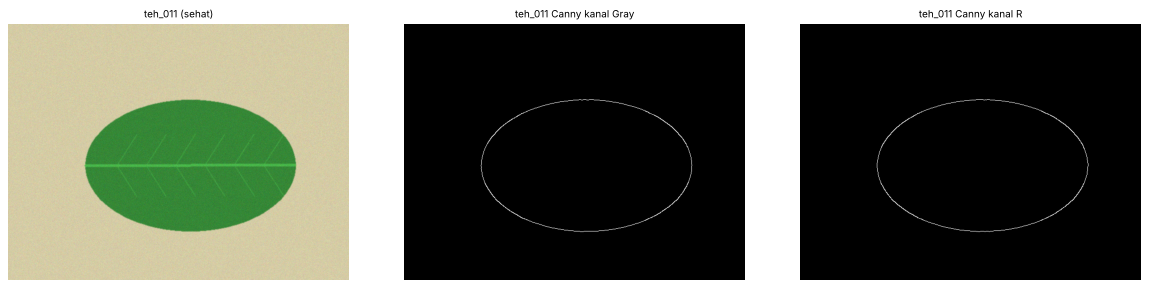

In [15]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0          # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
sehat.to_csv("../hasil/p5_tepi_sehat.csv", index=False)
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_sehat.png", bbox_inches="tight"); plt.show()

In [16]:
# Bukti tambahan P2.5: kontras tulang daun (garis tengah) vs tepi daun, kanal Gray vs R, daun sehat
baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gf = g.astype(np.float32)
        selisih = np.percentile(gf[dalam], 99) - np.median(gf[dalam])     # tulang daun vs daun
        tepi_d = abs(np.median(gf[(cv2.dilate(md, np.ones((9, 9), np.uint8)) > 0) & (md == 0)]) - np.median(gf[dalam]))  # latar vs daun
        row = [d.kondisi_cahaya, kanal, round(selisih, 1), round(tepi_d, 1)]
        for sg in [0, 1.0, 2.0]:
            row.append(int(((tepi_canny(g, 30, 90, sg) > 0) & dalam).sum()))
        baris.append(row)
tb = pd.DataFrame(baris, columns=["kondisi", "kanal", "kontras_tulang", "kontras_tepi_daun", "px_dalam_sigma0", "px_dalam_sigma1", "px_dalam_sigma2"])
print(tb.groupby("kanal").mean(numeric_only=True).round(1))
print(tb.groupby(["kondisi", "kanal"]).mean(numeric_only=True).round(1))

       kontras_tulang  kontras_tepi_daun  px_dalam_sigma0  px_dalam_sigma1  px_dalam_sigma2
kanal                                                                                      
Gray        30.200001          72.900002           2868.7            738.4              0.4
R           19.000000         114.099998           7114.8           1556.2              0.0
                      kontras_tulang  kontras_tepi_daun  px_dalam_sigma0  px_dalam_sigma1  px_dalam_sigma2
kondisi        kanal                                                                                      
bayangan       Gray        42.000000          76.800003           4574.5            975.5              2.0
               R           24.000000         113.500000           2358.5            144.2              0.0
gelap          Gray        34.799999          91.199997           5480.5            892.0              0.0
               R           21.500000         137.199997          20589.2           7434.5        

### Langkah 2.6 (Kerjakan sendiri) Keputusan pemakaian tepi (Tabel 8)

In [17]:
# Bukti untuk Tabel 8: F1 tepi daun saja dan tepi bercak saja (praproses, kanal R)
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    for nm, f in metode.items():
        e = f(g)
        baris.append([d.kondisi_cahaya, nm, *skor_tepi(e, ad), *skor_tepi(e, ab)])
bk = pd.DataFrame(baris, columns=["kondisi", "metode", "P_daun", "R_daun", "F1_daun", "P_bercak", "R_bercak", "F1_bercak"])
print(bk.groupby("metode")[["P_daun", "R_daun", "F1_daun", "P_bercak", "R_bercak", "F1_bercak"]].mean().round(3))
bk.to_csv("../hasil/p5_bukti_keputusan.csv", index=False)
# waktu proses per citra (ms) untuk kebutuhan pengguna nomor 4
import time
g = praproses(muat("teh_041.png")[0], PARAM)[:, :, 2]
for nm, f in metode.items():
    t = []
    for _ in range(20):
        t0 = time.perf_counter(); f(g); t.append(time.perf_counter() - t0)
    print(f"{nm:8s} {1000*np.mean(t):.2f} ms")

         P_daun  R_daun  F1_daun  P_bercak  R_bercak  F1_bercak
metode                                                         
Canny     0.825   0.992    0.895     0.165     0.891      0.258
LoG       0.723   0.996    0.825     0.184     0.992      0.289
Prewitt   0.716   0.989    0.820     0.158     0.940      0.252
Sobel     0.696   0.990    0.805     0.157     0.946      0.251
Sobel    2.65 ms
Prewitt  2.20 ms
LoG      2.44 ms


Canny    1.48 ms


**Tabel 8. Keputusan pemakaian deteksi tepi pada SIMUTEH**

| Keperluan | Dipakai? | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | Ya, sebagai pemeriksa/validasi (bukan jalur utama) | Canny kanal R sesudah praproses, σ = 2, 30/90; pada kontras rendah `canny_persentil` q = 98 | Tabel 6 (F1 0,972); Tabel 7; tabel persentil (R rerata 0,988, kontras rendah 0,992); F1 tepi daun saja 0,895 dengan recall 0,992 |
| Menemukan batas bercak | Ya, terbatas (penanda/validasi) | Canny kanal R σ = 2, 30/90 | R bercak 0,891 (Tabel 7); F1 tepi bercak saja hanya 0,258 karena presisi rendah (tepi daun ikut) |
| Mengisi wilayah bercak (segmentasi) | **Tidak** | - | Tepi hanya garis 1 piksel; luas diperoleh dari `bercak_awal` + morfologi (IoU 0,873 pada teh_041; akurasi kelas 98,3%) |
| Fitur bentuk bercak (P9) | Tidak langsung | Kontur dari komponen terlabel (`findContours`) | Kebulatan dan rasio aspek dari Kode 4.1/4.2 sudah cukup memisahkan bercak dari tulang daun |

In [18]:
# Langkah 2.7 Checkpoint: commit lalu beri tag (jalankan di terminal repository)
# git add . && git commit -m "P5: deteksi tepi dan keputusan pemakaian"
# git tag v0.2-tepi && git push && git push --tags
print('Tag v0.2-tepi dibuat dari terminal; lihat README untuk langkahnya.')

Tag v0.2-tepi dibuat dari terminal; lihat README untuk langkahnya.
